In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load the dataset
df = pd.read_parquet("../data/raw/yellow_tripdata_2024-01.parquet")
print(f"Shape of the dataset: {df.shape}")
df.head()

Shape of the dataset: (2964624, 19)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [3]:
# 1. Check missing values
print("--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Missing Values Percentage ---")
print((df.isnull().sum() / len(df)) * 100)

--- Missing Values Count ---
VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          140162
trip_distance                 0
RatecodeID               140162
store_and_fwd_flag       140162
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     140162
Airport_fee              140162
dtype: int64

--- Missing Values Percentage ---
VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          4.727817
trip_distance            0.000000
RatecodeID               4.727817
store_and_fwd_flag       4.727817
PULocationID             0.000000
DOLocationID             0.000000
payment_t

In [4]:
print("--- Data Quality Check ---")

# 1. Negative distance
neg_dist = df[df['trip_distance'] < 0]
print(f"Trips with negative distance: {len(neg_dist)}")

# 2. Zero or negative fare
bad_fare = df[df['fare_amount'] <= 0]
print(f"Trips with fare <= 0: {len(bad_fare)}")

# 3. Zero passengers
zero_pass = df[df['passenger_count'] == 0]
print(f"Trips with 0 passengers: {len(zero_pass)}")

# 4. Dropoff before pickup (impossible time travel)
bad_time = df[df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']]
print(f"Trips with dropoff before pickup: {len(bad_time)}")

# 5. Fully duplicated rows
duplicates = df.duplicated().sum()
print(f"Fully duplicated rows: {duplicates}")

--- Data Quality Check ---
Trips with negative distance: 0
Trips with fare <= 0: 38341
Trips with 0 passengers: 31465
Trips with dropoff before pickup: 56
Fully duplicated rows: 0


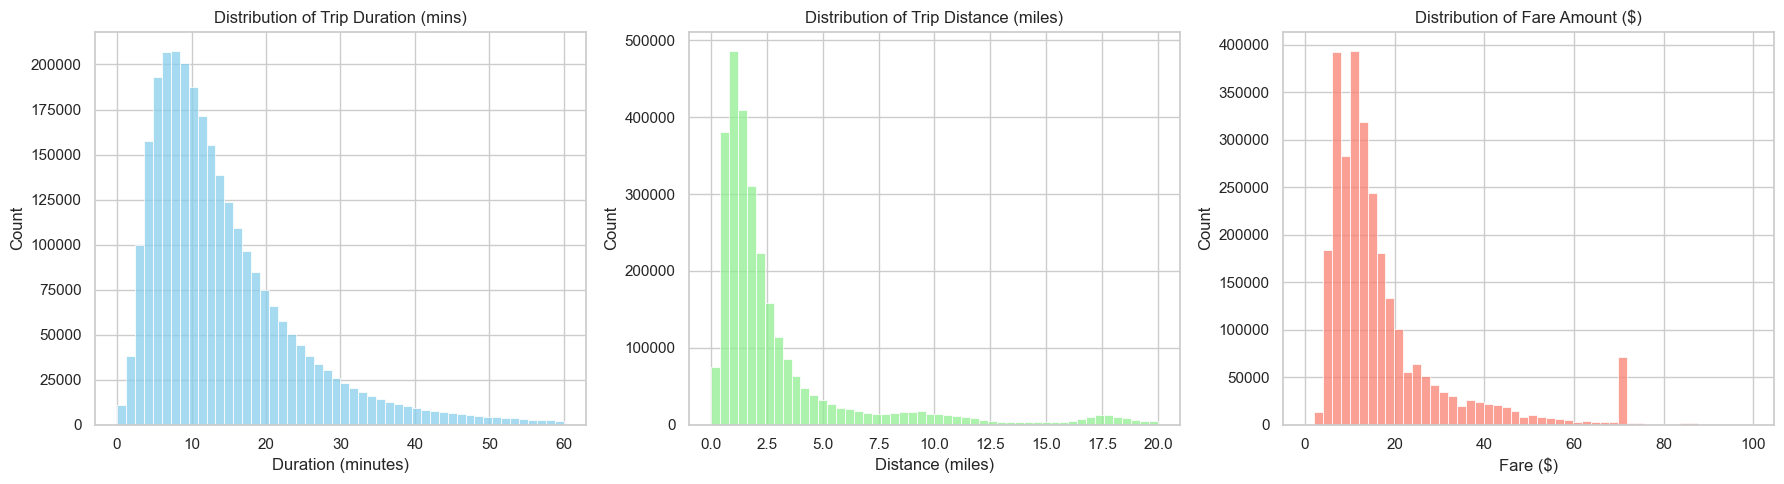

In [5]:
# Calculate trip duration in minutes
df['trip_duration_mins'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60

# Filter reasonable data for better visualization (0-60 mins, 0-20 miles, $0-$100)
df_clean = df[(df['trip_duration_mins'] > 0) & (df['trip_duration_mins'] < 60) & 
              (df['trip_distance'] > 0) & (df['trip_distance'] < 20) &
              (df['fare_amount'] > 0) & (df['fare_amount'] < 100)]

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram of trip duration
sns.histplot(df_clean['trip_duration_mins'], bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Trip Duration (mins)')
axes[0].set_xlabel('Duration (minutes)')

# Histogram of trip distance
sns.histplot(df_clean['trip_distance'], bins=50, ax=axes[1], color='lightgreen')
axes[1].set_title('Distribution of Trip Distance (miles)')
axes[1].set_xlabel('Distance (miles)')

# Histogram of fare amount
sns.histplot(df_clean['fare_amount'], bins=50, ax=axes[2], color='salmon')
axes[2].set_title('Distribution of Fare Amount ($)')
axes[2].set_xlabel('Fare ($)')

plt.tight_layout()
plt.show()

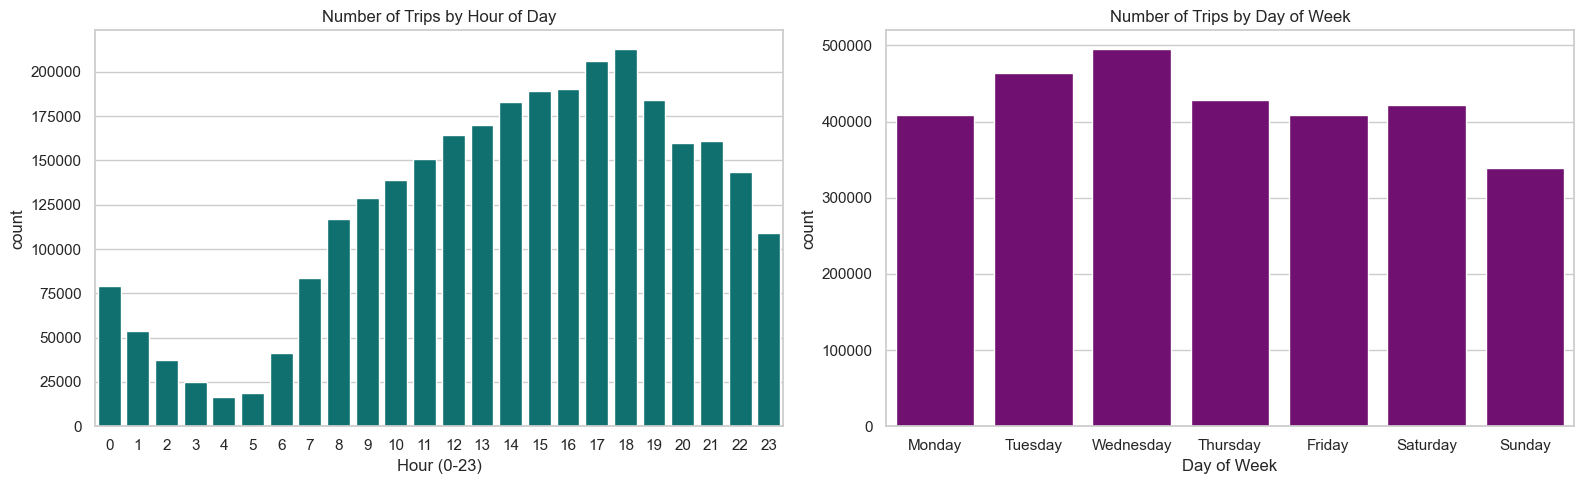

In [6]:
# Extract temporal features
df['hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_of_week'] = df['tpep_pickup_datetime'].dt.day_name()

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Trips by hour of day
sns.countplot(data=df, x='hour', ax=axes[0], color='teal')
axes[0].set_title('Number of Trips by Hour of Day')
axes[0].set_xlabel('Hour (0-23)')

# Trips by day of week (ordered)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df, x='day_of_week', ax=axes[1], order=days_order, color='purple')
axes[1].set_title('Number of Trips by Day of Week')
axes[1].set_xlabel('Day of Week')

plt.tight_layout()
plt.show()

Number of trips with speed > 100 mph (impossible): 1024


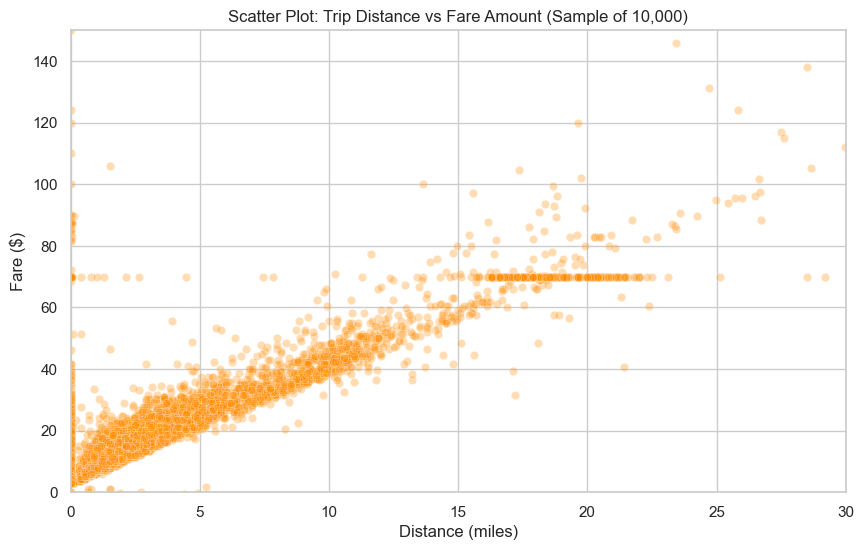

In [7]:
# Calculate speed in mph
df['speed_mph'] = (df['trip_distance'] / df['trip_duration_mins']) * 60

# Check impossible speeds
impossible_speed = df[(df['speed_mph'] > 100) & (df['trip_duration_mins'] > 0)]
print(f"Number of trips with speed > 100 mph (impossible): {len(impossible_speed)}")

# Scatter plot of distance vs fare (sample of 10,000 to avoid overplotting)
sample_df = df.sample(n=10000, random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_df, x='trip_distance', y='fare_amount', alpha=0.3, color='darkorange')
plt.title('Scatter Plot: Trip Distance vs Fare Amount (Sample of 10,000)')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.xlim(0, 30)
plt.ylim(0, 150)
plt.show()

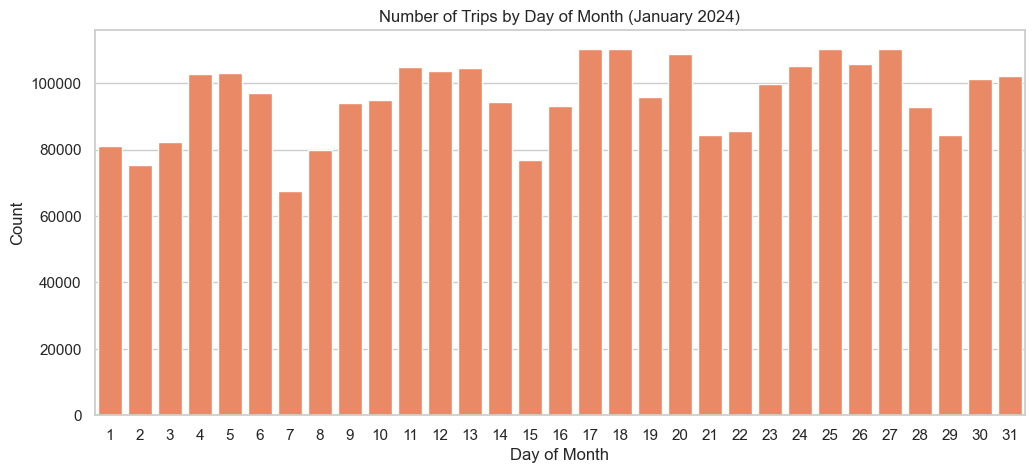

In [8]:
# Extract day of the month
df['day_of_month'] = df['tpep_pickup_datetime'].dt.day

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='day_of_month', color='coral')
plt.title('Number of Trips by Day of Month (January 2024)')
plt.xlabel('Day of Month')
plt.ylabel('Count')
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19736\2336119804.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pickups.index, y=top_pickups.values, palette='viridis')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19736\2336119804.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_dropoffs.index, y=top_dropoffs.values, palette='magma')


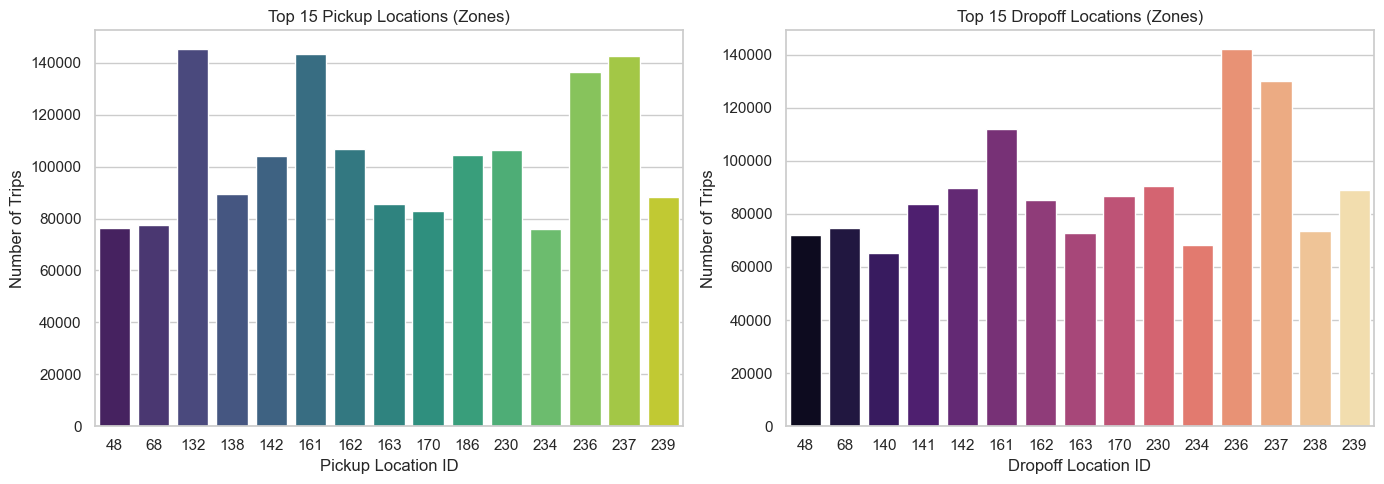

In [9]:
# Top 15 Pickup Locations
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
top_pickups = df['PULocationID'].value_counts().head(15)
sns.barplot(x=top_pickups.index, y=top_pickups.values, palette='viridis')
plt.title('Top 15 Pickup Locations (Zones)')
plt.xlabel('Pickup Location ID')
plt.ylabel('Number of Trips')

# Top 15 Dropoff Locations
plt.subplot(1, 2, 2)
top_dropoffs = df['DOLocationID'].value_counts().head(15)
sns.barplot(x=top_dropoffs.index, y=top_dropoffs.values, palette='magma')
plt.title('Top 15 Dropoff Locations (Zones)')
plt.xlabel('Dropoff Location ID')
plt.ylabel('Number of Trips')

plt.tight_layout()
plt.show()